In [1]:

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE

IMG_SIZE = (224, 224)
NUM_CLASSES = 37

EPOCHS = 5

print("Seed:", SEED)
print("Image size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)

Seed: 42
Image size: (224, 224)
Number of classes: 37


In [3]:

import tensorflow_datasets as tfds

(ds_train_full, ds_test), ds_info = tfds.load(
    "oxford_iiit_pet",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print("Training samples:", ds_info.splits["train"].num_examples)
print("Test samples:", ds_info.splits["test"].num_examples)
print("Number of classes:", ds_info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord*...…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord*...:…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Training samples: 3680
Test samples: 3669
Number of classes: 37


In [4]:

TRAIN_SIZE = 0.8

total_train = ds_info.splits["train"].num_examples
train_count = int(total_train * TRAIN_SIZE)

ds_train_full = ds_train_full.shuffle(
    total_train,
    seed=SEED,
    reshuffle_each_iteration=False
)

ds_train = ds_train_full.take(train_count)
ds_val = ds_train_full.skip(train_count)

print("Train:", train_count)
print("Validation:", total_train - train_count)
print("Test:", ds_info.splits["test"].num_examples)

Train: 2944
Validation: 736
Test: 3669


In [5]:

def preprocess_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    image = preprocess_input(image)

    return image, label


def prepare_dataset(dataset, batch_size=32, shuffle=False):
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            1000,
            seed=SEED
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

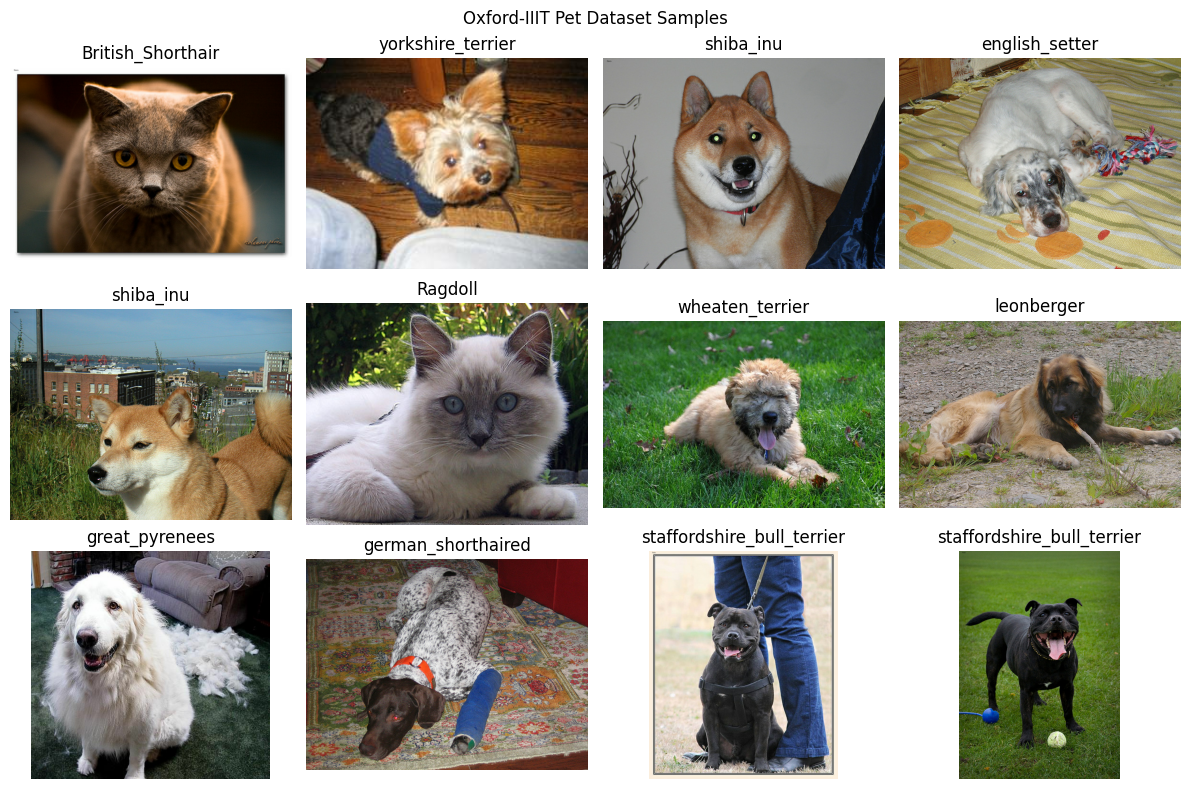

In [6]:

plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(ds_train.take(12)):
    plt.subplot(3, 4, i + 1)

    plt.imshow(image)
    plt.title(ds_info.features["label"].int2str(label.numpy()))
    plt.axis("off")

plt.suptitle("Oxford-IIIT Pet Dataset Samples")
plt.tight_layout()
plt.show()

In [7]:

def build_mobilenet_model(
    initialization="he",
    dropout_rate=0.0,
    l2_strength=0.0,
    use_bn=True,
    optimizer_name="adam",
    learning_rate=1e-3,
    train_base=False,
    fine_tune_layers=0
):

    # --------------------------------------------------------
    # MobileNetV2 base
    # --------------------------------------------------------

    base = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )

    base.trainable = train_base

    # Fine-tuning
    if train_base and fine_tune_layers > 0:

        for layer in base.layers[:-fine_tune_layers]:
            layer.trainable = False

        for layer in base.layers[-fine_tune_layers:]:
            layer.trainable = True

    # --------------------------------------------------------
    # Classifier
    # --------------------------------------------------------

    inputs = layers.Input(shape=(224, 224, 3))

    x = base(inputs, training=train_base)

    x = layers.GlobalAveragePooling2D()(x)

    # Batch Normalization
    if use_bn:
        x = layers.BatchNormalization()(x)

    # Dropout
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    # Regularization
    kernel_regularizer = None

    if l2_strength > 0:
        kernel_regularizer = regularizers.l2(l2_strength)

    # Initialization
    if initialization == "zero":
        initializer = tf.keras.initializers.Zeros()

    elif initialization == "random":
        initializer = tf.keras.initializers.RandomNormal(
            mean=0.0,
            stddev=0.05,
            seed=SEED
        )

    elif initialization == "xavier":
        initializer = tf.keras.initializers.GlorotUniform(
            seed=SEED
        )

    elif initialization == "he":
        initializer = tf.keras.initializers.HeNormal(
            seed=SEED
        )

    else:
        raise ValueError("Unknown initialization")

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        kernel_initializer=initializer,
        kernel_regularizer=kernel_regularizer
    )(x)

    model = models.Model(inputs, outputs)

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    if optimizer_name == "sgd":

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    elif optimizer_name == "momentum":

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    elif optimizer_name == "rmsprop":

        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    elif optimizer_name == "adam":

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    else:
        raise ValueError("Unknown optimizer")

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [8]:

def train_model(
    model,
    train_dataset,
    val_dataset,
    epochs=EPOCHS,
    verbose=1
):

    start_time = time.time()

    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        verbose=verbose
    )

    training_time = time.time() - start_time

    return history, training_time

In [9]:

def plot_loss_comparison(histories, title="Training Loss"):
    plt.figure(figsize=(10, 6))

    for name, history in histories.items():
        plt.plot(
            history.history["loss"],
            label=name
        )

    plt.xlabel("Epoch")
    plt.ylabel("Training Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_val_accuracy_comparison(
    histories,
    title="Validation Accuracy"
):

    plt.figure(figsize=(10, 6))

    for name, history in histories.items():
        plt.plot(
            np.array(history.history["val_accuracy"]) * 100,
            label=name
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_train_val_accuracy(history, title):

    plt.figure(figsize=(10, 6))

    plt.plot(
        np.array(history.history["accuracy"]) * 100,
        label="Training Accuracy"
    )

    plt.plot(
        np.array(history.history["val_accuracy"]) * 100,
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_train_val_loss(history, title):

    plt.figure(figsize=(10, 6))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [10]:

train_ds = prepare_dataset(
    ds_train,
    batch_size=32,
    shuffle=True
)

val_ds = prepare_dataset(
    ds_val,
    batch_size=32,
    shuffle=False
)

test_ds = prepare_dataset(
    ds_test,
    batch_size=32,
    shuffle=False
)

baseline_model = build_mobilenet_model(
    initialization="he",
    dropout_rate=0,
    l2_strength=0,
    use_bn=True,
    optimizer_name="adam",
    learning_rate=1e-3,
    train_base=False
)

baseline_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │        47,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,310,501 (8.81 MB)

 Trainable params: 49,957 (195.14 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [11]:

baseline_history, baseline_time = train_model(
    baseline_model,
    train_ds,
    val_ds
)

print("Training time:", baseline_time, "seconds")

Epoch 1/5


2026-08-20 08:56:50.634147: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 08:56:50.772319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1787216212.662506     182 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


92/92 ━━━━━━━━━━━━━━━━━━━━ 34s 133ms/step - accuracy: 0.6848 - loss: 1.0970 - val_accuracy: 0.8791 - val_loss: 0.5128
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9283 - loss: 0.2410 - val_accuracy: 0.9076 - val_loss: 0.3269
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9688 - loss: 0.1347 - val_accuracy: 0.9117 - val_loss: 0.2827
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9868 - loss: 0.0787 - val_accuracy: 0.9171 - val_loss: 0.2725
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9932 - loss: 0.0549 - val_accuracy: 0.9212 - val_loss: 0.2667
Training time: 80.06875610351562 seconds


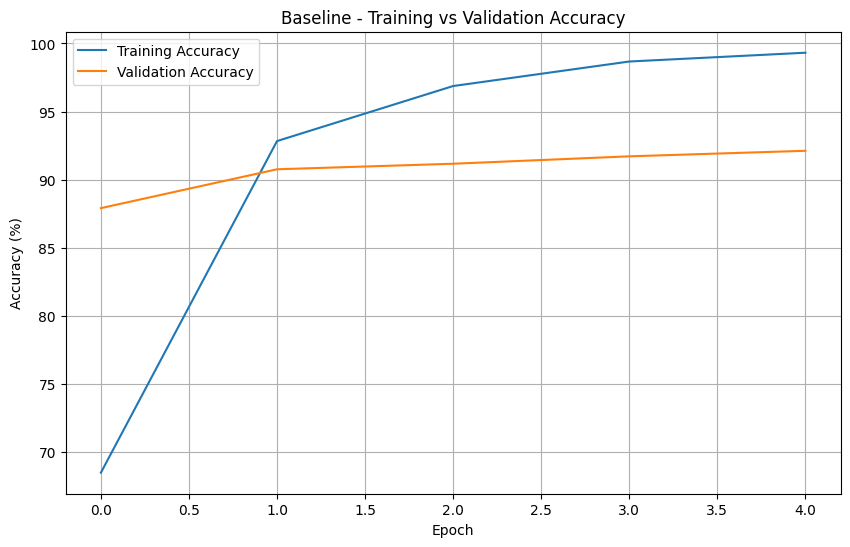

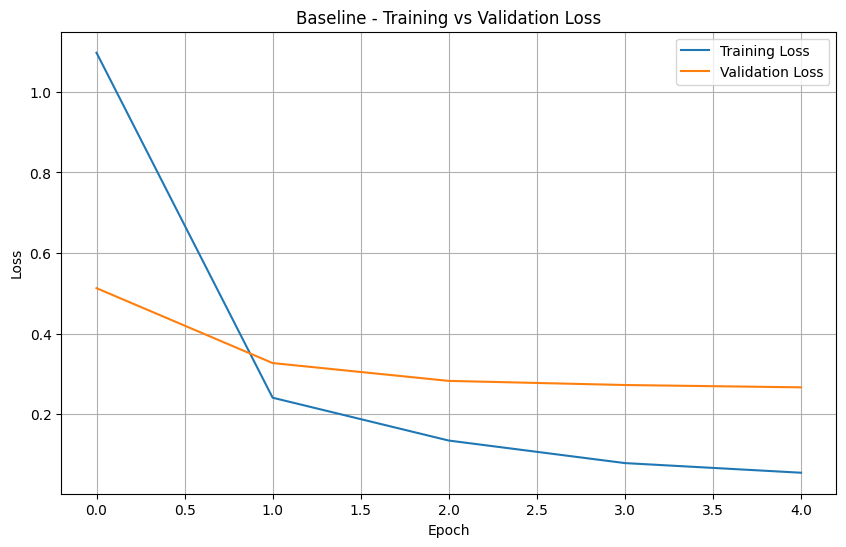

In [12]:
plot_train_val_accuracy(
    baseline_history,
    "Baseline - Training vs Validation Accuracy"
)

plot_train_val_loss(
    baseline_history,
    "Baseline - Training vs Validation Loss"
)

In [13]:

initializations = [
    "zero",
    "random",
    "xavier",
    "he"
]

init_histories = {}
init_results = {}

for init in initializations:

    print("Initialization:", init)

    model = build_mobilenet_model(
        initialization=init,
        dropout_rate=0,
        l2_strength=0,
        use_bn=True,
        optimizer_name="adam",
        learning_rate=1e-3,
        train_base=False
    )

    history, training_time = train_model(
        model,
        train_ds,
        val_ds,
        epochs=EPOCHS
    )

    init_histories[init] = history

    init_results[init] = {
        "Best Validation Accuracy":
            max(history.history["val_accuracy"]) * 100,

        "Final Training Loss":
            history.history["loss"][-1],

        "Training Time":
            training_time
    }

init_results_df = pd.DataFrame(init_results).T

display(init_results_df)

Initialization: zero
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 131ms/step - accuracy: 0.8305 - loss: 0.7630 - val_accuracy: 0.9103 - val_loss: 0.4236
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9562 - loss: 0.1697 - val_accuracy: 0.9239 - val_loss: 0.2751
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9840 - loss: 0.0903 - val_accuracy: 0.9212 - val_loss: 0.2437
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9939 - loss: 0.0567 - val_accuracy: 0.9293 - val_loss: 0.2221
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9990 - loss: 0.0353 - val_accuracy: 0.9280 - val_loss: 0.2273
Initialization: random
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 131ms/step - accuracy: 0.6382 - loss: 1.3463 - val_accuracy: 0.8655 - val_loss: 0.5480
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9144 - loss: 0.2737 - val_accuracy: 0.8886 - val_loss: 0.3764
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.

,Best Validation Accuracy,Final Training Loss,Training Time
zero,92.934781,0.035315,70.282893
random,90.896738,0.056862,71.393601
xavier,90.896738,0.053086,71.513663
he,91.983694,0.058329,70.749996


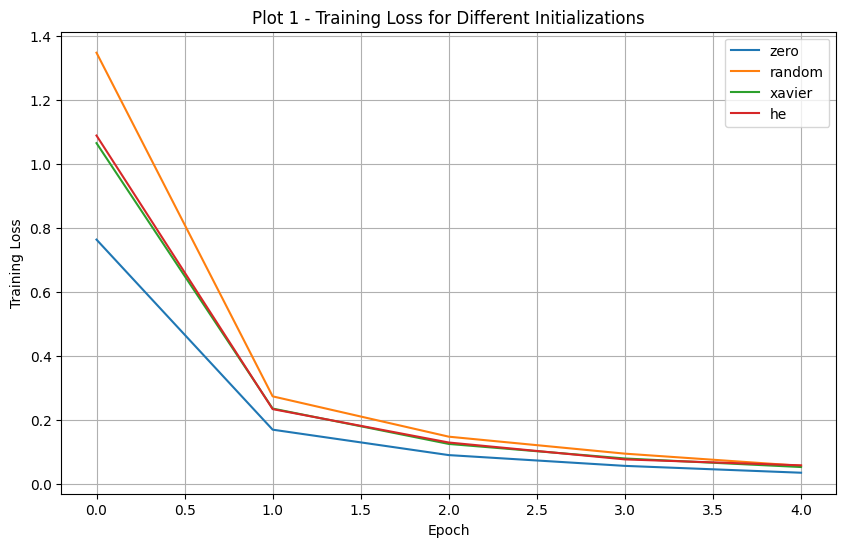

In [14]:
plot_loss_comparison(
    init_histories,
    "Plot 1 - Training Loss for Different Initializations"
)

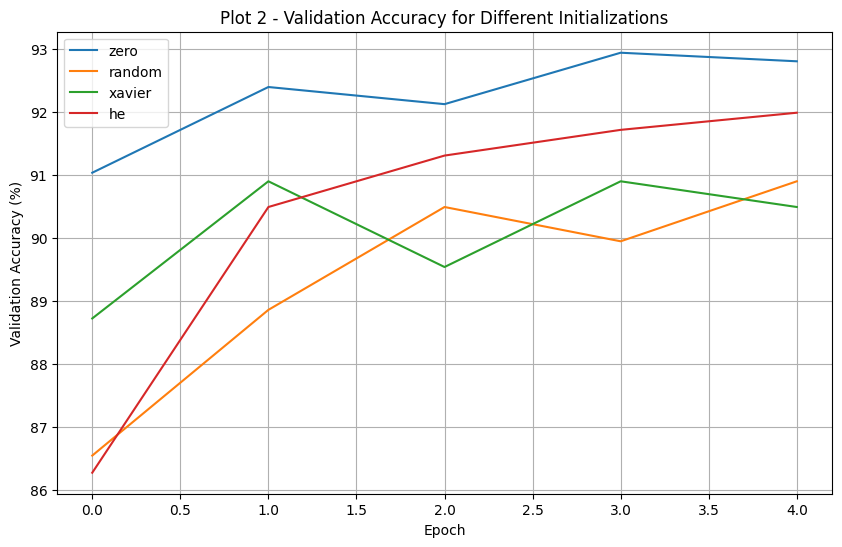

In [15]:

plot_val_accuracy_comparison(
    init_histories,
    "Plot 2 - Validation Accuracy for Different Initializations"
)

In [16]:

regularization_configs = {

    "No Regularization": {
        "l2_strength": 0,
        "dropout_rate": 0,
        "use_bn": False
    },

    "L2": {
        "l2_strength": 1e-4,
        "dropout_rate": 0,
        "use_bn": False
    },

    "Dropout": {
        "l2_strength": 0,
        "dropout_rate": 0.5,
        "use_bn": False
    },

    "Batch Normalization": {
        "l2_strength": 0,
        "dropout_rate": 0,
        "use_bn": True
    }
}

regularization_histories = {}
regularization_results = {}

for name, config in regularization_configs.items():

    print(name)
    model = build_mobilenet_model(
        initialization="he",
        optimizer_name="adam",
        learning_rate=1e-3,
        train_base=False,
        **config
    )

    history, training_time = train_model(
        model,
        train_ds,
        val_ds
    )

    regularization_histories[name] = history

    regularization_results[name] = {
        "Best Val Accuracy":
            max(history.history["val_accuracy"]) * 100,

        "Final Train Accuracy":
            history.history["accuracy"][-1] * 100,

        "Final Val Accuracy":
            history.history["val_accuracy"][-1] * 100,

        "Final Train Loss":
            history.history["loss"][-1],

        "Final Val Loss":
            history.history["val_loss"][-1],

        "Training Time":
            training_time
    }

regularization_df = pd.DataFrame(
    regularization_results
).T

display(regularization_df)

No Regularization
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - accuracy: 0.6821 - loss: 1.3243 - val_accuracy: 0.9117 - val_loss: 0.4431
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9226 - loss: 0.3230 - val_accuracy: 0.9103 - val_loss: 0.3234
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9538 - loss: 0.2059 - val_accuracy: 0.9171 - val_loss: 0.2833
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9718 - loss: 0.1446 - val_accuracy: 0.9266 - val_loss: 0.2588
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9854 - loss: 0.1058 - val_accuracy: 0.9280 - val_loss: 0.2443
L2
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 131ms/step - accuracy: 0.6824 - loss: 1.3261 - val_accuracy: 0.9035 - val_loss: 0.4474
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9276 - loss: 0.3325 - val_accuracy: 0.9239 - val_loss: 0.3311
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9589 - loss: 0.2160 - v

,Best Val Accuracy,Final Train Accuracy,Final Val Accuracy,Final Train Loss,Final Val Loss,Training Time
No Regularization,92.798913,98.539400,92.798913,0.105814,0.244272,68.972376
L2,93.070650,98.437500,93.070650,0.118806,0.257429,70.089045
Dropout,92.798913,92.595106,92.798913,0.239383,0.259087,68.748166
Batch Normalization,92.391306,99.354619,91.440219,0.053054,0.279058,70.047630


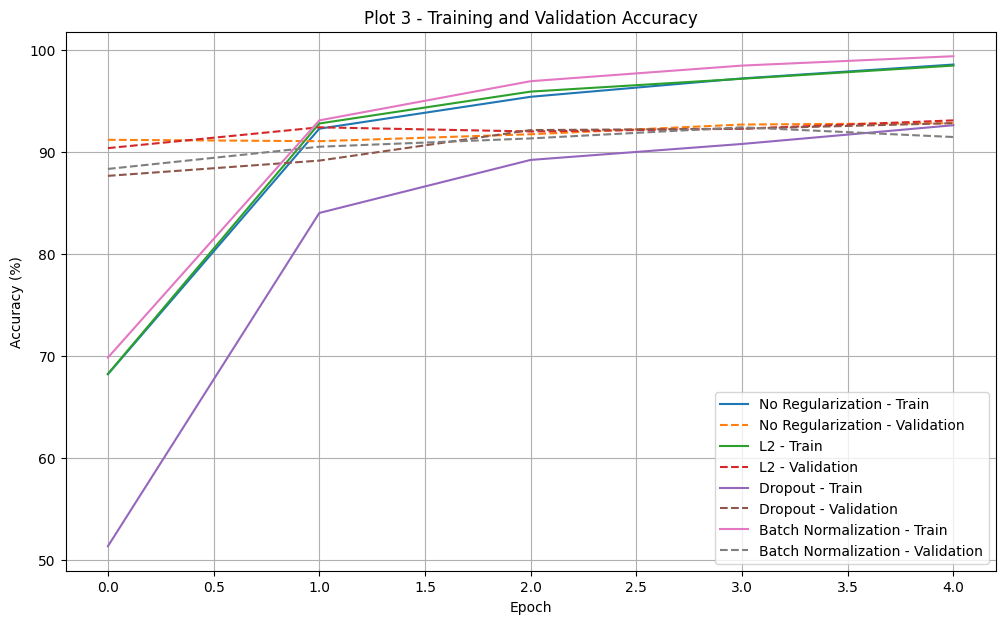

In [17]:

plt.figure(figsize=(12, 7))

for name, history in regularization_histories.items():

    plt.plot(
        np.array(history.history["accuracy"]) * 100,
        label=f"{name} - Train"
    )

    plt.plot(
        np.array(history.history["val_accuracy"]) * 100,
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Plot 3 - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

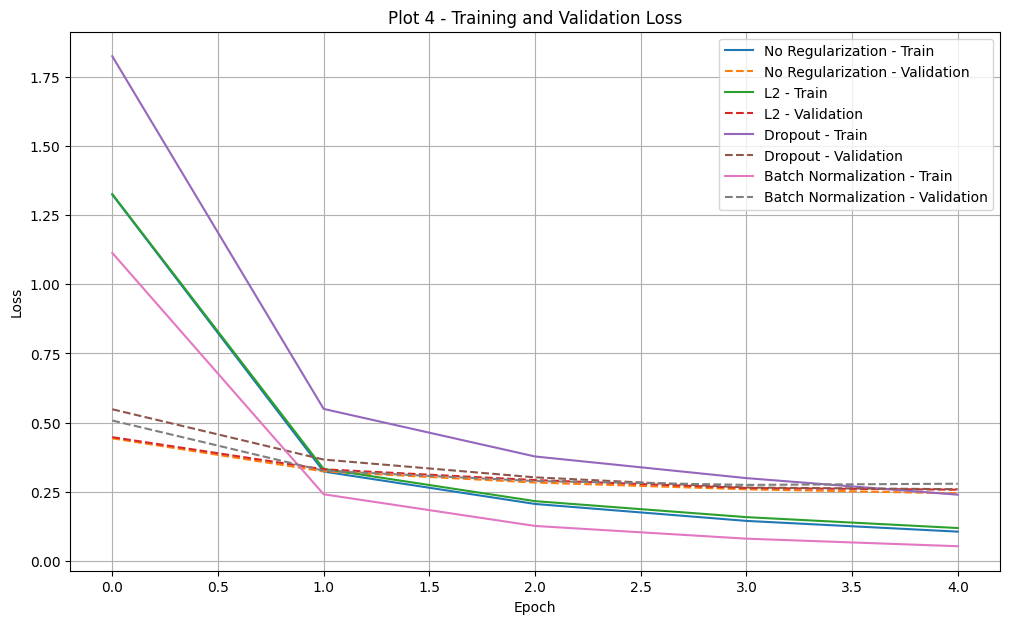

In [18]:

plt.figure(figsize=(12, 7))

for name, history in regularization_histories.items():

    plt.plot(
        history.history["loss"],
        label=f"{name} - Train"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Plot 4 - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [19]:

bn_configs = {
    "With BN": True,
    "Without BN": False
}

bn_histories = {}

for name, use_bn in bn_configs.items():

    model = build_mobilenet_model(
        initialization="he",
        dropout_rate=0,
        l2_strength=0,
        use_bn=use_bn,
        optimizer_name="adam",
        learning_rate=1e-3,
        train_base=False
    )

    history, _ = train_model(
        model,
        train_ds,
        val_ds
    )

    bn_histories[name] = history

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - accuracy: 0.6960 - loss: 1.1180 - val_accuracy: 0.8832 - val_loss: 0.5101
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9243 - loss: 0.2417 - val_accuracy: 0.9090 - val_loss: 0.3207
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9650 - loss: 0.1325 - val_accuracy: 0.9130 - val_loss: 0.2850
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9864 - loss: 0.0816 - val_accuracy: 0.9198 - val_loss: 0.2770
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9915 - loss: 0.0545 - val_accuracy: 0.9198 - val_loss: 0.2770
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 131ms/step - accuracy: 0.6773 - loss: 1.3435 - val_accuracy: 0.9062 - val_loss: 0.4333
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.9246 - loss: 0.3241 - val_accuracy: 0.9212 - val_loss: 0.3114
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9511 - loss: 0.2078 - val_accuracy: 0.9266 -

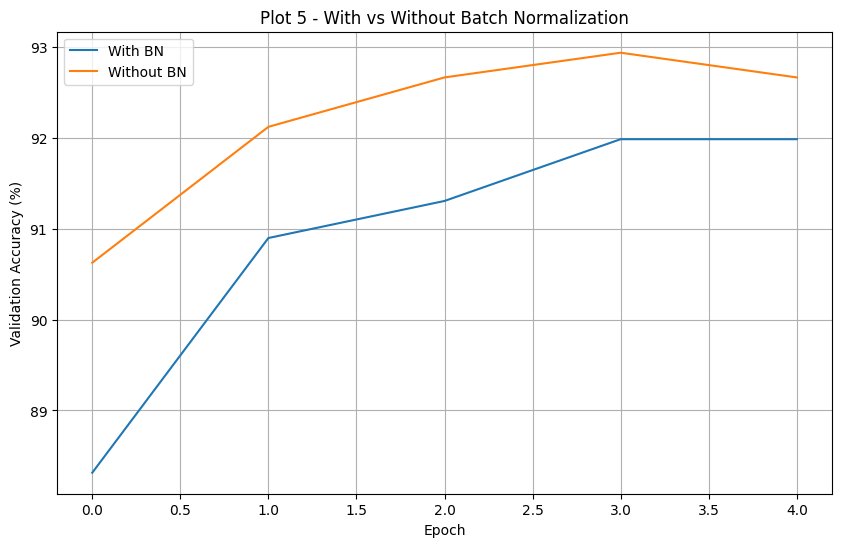

In [20]:

plot_val_accuracy_comparison(
    bn_histories,
    "Plot 5 - With vs Without Batch Normalization"
)

In [21]:

optimizers = [
    "sgd",
    "momentum",
    "rmsprop",
    "adam"
]

optimizer_histories = {}
optimizer_results = {}

for optimizer_name in optimizers:
    print("Optimizer:", optimizer_name)

    model = build_mobilenet_model(
        initialization="he",
        dropout_rate=0,
        l2_strength=0,
        use_bn=True,
        optimizer_name=optimizer_name,
        learning_rate=1e-3,
        train_base=False
    )

    history, training_time = train_model(
        model,
        train_ds,
        val_ds
    )

    optimizer_histories[optimizer_name] = history

    optimizer_results[optimizer_name] = {
        "Final Loss":
            history.history["loss"][-1],

        "Best Val Accuracy":
            max(history.history["val_accuracy"]) * 100,

        "Final Val Accuracy":
            history.history["val_accuracy"][-1] * 100,

        "Training Time":
            training_time
    }

optimizer_df = pd.DataFrame(
    optimizer_results
).T

display(optimizer_df)

Optimizer: sgd
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 131ms/step - accuracy: 0.0445 - loss: 4.1758 - val_accuracy: 0.0842 - val_loss: 3.4927
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.1467 - loss: 3.2388 - val_accuracy: 0.2337 - val_loss: 2.8391
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.3071 - loss: 2.5305 - val_accuracy: 0.4008 - val_loss: 2.2295
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.4599 - loss: 2.0129 - val_accuracy: 0.5421 - val_loss: 1.7638
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.5700 - loss: 1.6280 - val_accuracy: 0.6345 - val_loss: 1.4398
Optimizer: momentum
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - accuracy: 0.4283 - loss: 2.2265 - val_accuracy: 0.8057 - val_loss: 1.1076
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.8353 - loss: 0.6050 - val_accuracy: 0.8764 - val_loss: 0.5633
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.8920 - lo

,Final Loss,Best Val Accuracy,Final Val Accuracy,Training Time
sgd,1.627966,63.451087,63.451087,70.404788
momentum,0.274722,90.353262,90.353262,69.037740
rmsprop,0.042382,90.896738,90.896738,69.619941
adam,0.054768,91.711956,91.711956,69.870371


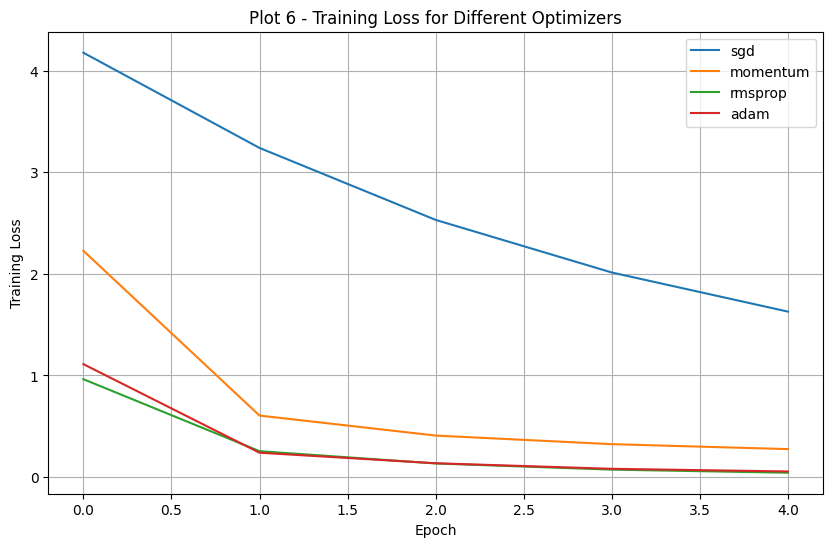

In [22]:

plot_loss_comparison(
    optimizer_histories,
    "Plot 6 - Training Loss for Different Optimizers"
)

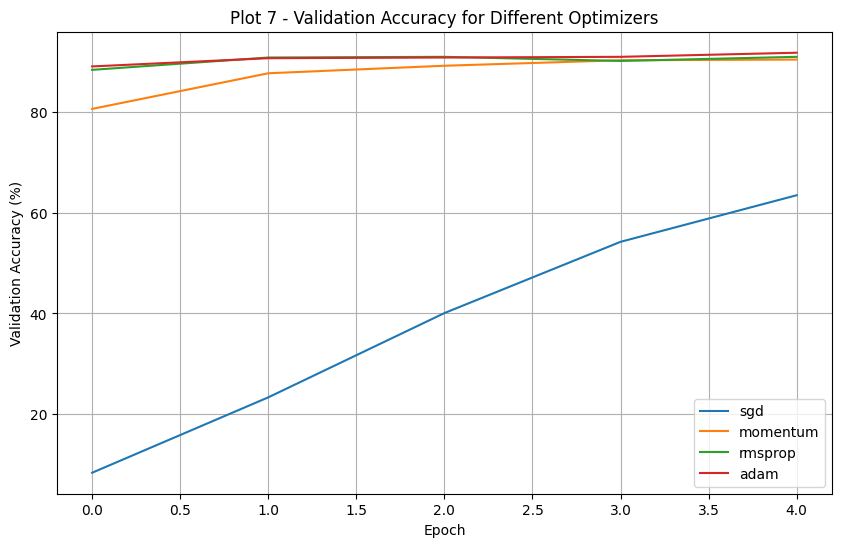

In [23]:
plot_val_accuracy_comparison(
    optimizer_histories,
    "Plot 7 - Validation Accuracy for Different Optimizers"
)

In [24]:

learning_rates = [1e-3, 1e-4]

lr_results = []

for lr in learning_rates:

    print("Learning rate:", lr)

    model = build_mobilenet_model(
        initialization="he",
        dropout_rate=0,
        l2_strength=0,
        use_bn=True,
        optimizer_name="adam",
        learning_rate=lr,
        train_base=False
    )

    history, _ = train_model(
        model,
        train_ds,
        val_ds
    )

    lr_results.append({
        "Learning Rate": lr,
        "Validation Accuracy":
            max(history.history["val_accuracy"]) * 100
    })

lr_df = pd.DataFrame(lr_results)

display(lr_df)

Learning rate: 0.001
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 140ms/step - accuracy: 0.6878 - loss: 1.1206 - val_accuracy: 0.8791 - val_loss: 0.5130
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.9304 - loss: 0.2417 - val_accuracy: 0.9158 - val_loss: 0.3195
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.9677 - loss: 0.1302 - val_accuracy: 0.9076 - val_loss: 0.2846
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9868 - loss: 0.0794 - val_accuracy: 0.9158 - val_loss: 0.2761
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9946 - loss: 0.0518 - val_accuracy: 0.9130 - val_loss: 0.2773
Learning rate: 0.0001
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 131ms/step - accuracy: 0.1192 - loss: 3.5727 - val_accuracy: 0.2853 - val_loss: 2.7069
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.4657 - loss: 1.9455 - val_accuracy: 0.6141 - val_loss: 1.6082
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.6

,Learning Rate,Validation Accuracy
0,0.0010,91.576087
1,0.0001,84.239131


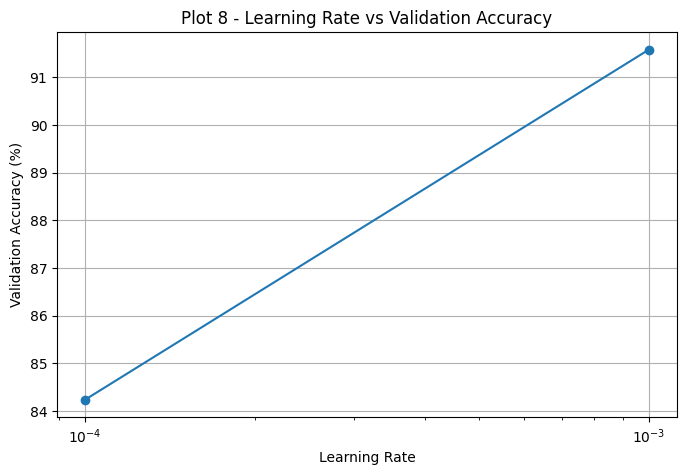

In [25]:

plt.figure(figsize=(8, 5))

plt.plot(
    lr_df["Learning Rate"],
    lr_df["Validation Accuracy"],
    marker="o"
)

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy (%)")
plt.title("Plot 8 - Learning Rate vs Validation Accuracy")
plt.grid(True)

plt.show()

In [26]:

batch_sizes = [16, 32, 64]

batch_results = []

for batch_size in batch_sizes:

    print("Batch size:", batch_size)

    current_train_ds = prepare_dataset(
        ds_train,
        batch_size=batch_size,
        shuffle=True
    )

    current_val_ds = prepare_dataset(
        ds_val,
        batch_size=batch_size,
        shuffle=False
    )

    model = build_mobilenet_model(
        initialization="he",
        dropout_rate=0,
        l2_strength=0,
        use_bn=True,
        optimizer_name="adam",
        learning_rate=1e-3,
        train_base=False
    )

    history, _ = train_model(
        model,
        current_train_ds,
        current_val_ds
    )

    batch_results.append({
        "Batch Size": batch_size,
        "Validation Accuracy":
            max(history.history["val_accuracy"]) * 100
    })

batch_df = pd.DataFrame(batch_results)

display(batch_df)

Batch size: 16
Epoch 1/5


2026-08-20 09:20:53.827973: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:20:53.966852: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:20:54.103082: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


184/184 ━━━━━━━━━━━━━━━━━━━━ 33s 70ms/step - accuracy: 0.7238 - loss: 0.9595 - val_accuracy: 0.9103 - val_loss: 0.3607
Epoch 2/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - accuracy: 0.9283 - loss: 0.2319 - val_accuracy: 0.9062 - val_loss: 0.3114
Epoch 3/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.9654 - loss: 0.1204 - val_accuracy: 0.9008 - val_loss: 0.2970
Epoch 4/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.9844 - loss: 0.0738 - val_accuracy: 0.9171 - val_loss: 0.2873
Epoch 5/5
184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - accuracy: 0.9898 - loss: 0.0509 - val_accuracy: 0.9226 - val_loss: 0.2769
Batch size: 32
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 132ms/step - accuracy: 0.6848 - loss: 1.0970 - val_accuracy: 0.8791 - val_loss: 0.5128
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9283 - loss: 0.2410 - val_accuracy: 0.9076 - val_loss: 0.3269
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9688 - loss: 0.1347 - val_accu

2026-08-20 09:23:27.930346: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:23:28.070067: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


46/46 ━━━━━━━━━━━━━━━━━━━━ 37s 332ms/step - accuracy: 0.6182 - loss: 1.4080 - val_accuracy: 0.8560 - val_loss: 0.7560
Epoch 2/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 157ms/step - accuracy: 0.9188 - loss: 0.2809 - val_accuracy: 0.8954 - val_loss: 0.4491
Epoch 3/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 150ms/step - accuracy: 0.9538 - loss: 0.1698 - val_accuracy: 0.8981 - val_loss: 0.3501
Epoch 4/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.9806 - loss: 0.1077 - val_accuracy: 0.9103 - val_loss: 0.3009
Epoch 5/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.9908 - loss: 0.0763 - val_accuracy: 0.9117 - val_loss: 0.2780


,Batch Size,Validation Accuracy
0,16,92.255437
1,32,92.119563
2,64,91.168481


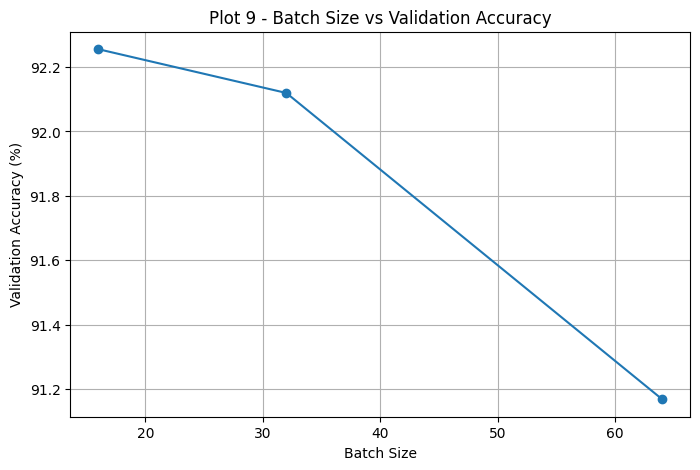

In [27]:

plt.figure(figsize=(8, 5))

plt.plot(
    batch_df["Batch Size"],
    batch_df["Validation Accuracy"],
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Validation Accuracy (%)")
plt.title("Plot 9 - Batch Size vs Validation Accuracy")
plt.grid(True)

plt.show()

In [28]:

dropout_rates = [0, 0.25, 0.5]

dropout_results = []

for dropout in dropout_rates:

    print("Dropout:", dropout)

    model = build_mobilenet_model(
        initialization="he",
        dropout_rate=dropout,
        l2_strength=0,
        use_bn=True,
        optimizer_name="adam",
        learning_rate=1e-3,
        train_base=False
    )

    history, _ = train_model(
        model,
        train_ds,
        val_ds
    )

    dropout_results.append({
        "Dropout Rate": dropout,
        "Validation Accuracy":
            max(history.history["val_accuracy"]) * 100
    })

dropout_df = pd.DataFrame(dropout_results)

display(dropout_df)

Dropout: 0
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 130ms/step - accuracy: 0.6912 - loss: 1.1237 - val_accuracy: 0.8981 - val_loss: 0.5019
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9293 - loss: 0.2413 - val_accuracy: 0.9062 - val_loss: 0.3246
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9650 - loss: 0.1345 - val_accuracy: 0.9144 - val_loss: 0.2764
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.9823 - loss: 0.0797 - val_accuracy: 0.9171 - val_loss: 0.2665
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.9915 - loss: 0.0608 - val_accuracy: 0.9130 - val_loss: 0.2701
Dropout: 0.25
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 131ms/step - accuracy: 0.6219 - loss: 1.3686 - val_accuracy: 0.8777 - val_loss: 0.5332
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.8927 - loss: 0.3314 - val_accuracy: 0.9062 - val_loss: 0.3369
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.9355 - loss: 0.2030

,Dropout Rate,Validation Accuracy
0,0.00,91.711956
1,0.25,91.983694
2,0.50,92.255437


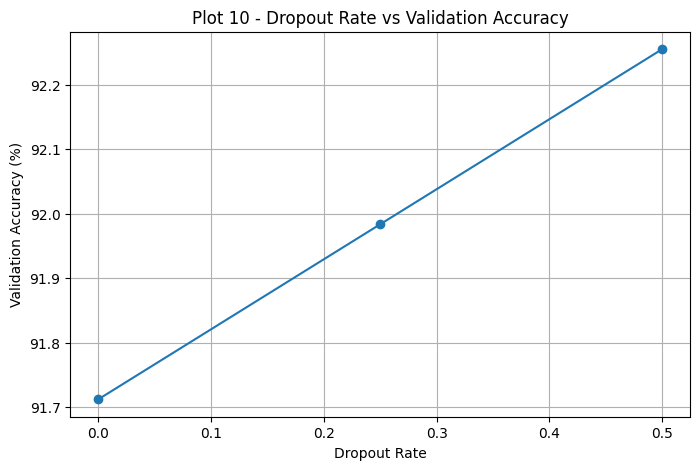

In [29]:

plt.figure(figsize=(8, 5))

plt.plot(
    dropout_df["Dropout Rate"],
    dropout_df["Validation Accuracy"],
    marker="o"
)

plt.xlabel("Dropout Rate")
plt.ylabel("Validation Accuracy (%)")
plt.title("Plot 10 - Dropout Rate vs Validation Accuracy")
plt.grid(True)

plt.show()

In [30]:

feature_extraction_model = build_mobilenet_model(
    initialization="he",
    dropout_rate=0.25,
    l2_strength=0,
    use_bn=True,
    optimizer_name="adam",
    learning_rate=1e-3,
    train_base=False
)

feature_history, feature_time = train_model(
    feature_extraction_model,
    train_ds,
    val_ds,
    epochs=EPOCHS
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 129ms/step - accuracy: 0.6321 - loss: 1.3338 - val_accuracy: 0.8777 - val_loss: 0.5353
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.8933 - loss: 0.3338 - val_accuracy: 0.9144 - val_loss: 0.3264
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9355 - loss: 0.2077 - val_accuracy: 0.9185 - val_loss: 0.2799
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9562 - loss: 0.1377 - val_accuracy: 0.9158 - val_loss: 0.2725
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9728 - loss: 0.1014 - val_accuracy: 0.9198 - val_loss: 0.2709


In [31]:

fine_tune_model = build_mobilenet_model(
    initialization="he",
    dropout_rate=0.25,
    l2_strength=0,
    use_bn=True,
    optimizer_name="adam",
    learning_rate=1e-5,
    train_base=True,
    fine_tune_layers=20
)

fine_history, fine_time = train_model(
    fine_tune_model,
    train_ds,
    val_ds,
    epochs=EPOCHS
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - accuracy: 0.0520 - loss: 4.3073 - val_accuracy: 0.1359 - val_loss: 3.2701
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.2041 - loss: 3.0531 - val_accuracy: 0.3818 - val_loss: 2.3614
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.3967 - loss: 2.1712 - val_accuracy: 0.5652 - val_loss: 1.6172
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.5713 - loss: 1.5788 - val_accuracy: 0.6929 - val_loss: 1.1490
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.6800 - loss: 1.1578 - val_accuracy: 0.7554 - val_loss: 0.8793


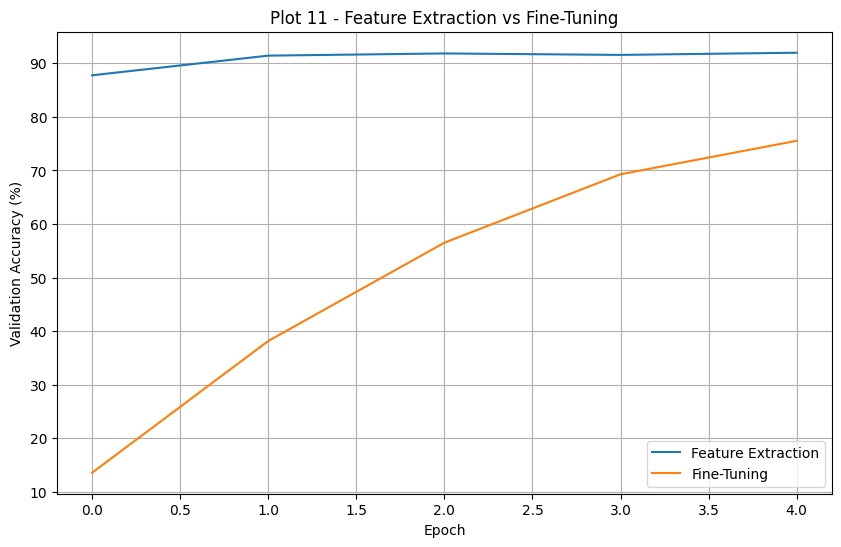

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    np.array(feature_history.history["val_accuracy"]) * 100,
    label="Feature Extraction"
)

plt.plot(
    np.array(fine_history.history["val_accuracy"]) * 100,
    label="Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Plot 11 - Feature Extraction vs Fine-Tuning")
plt.legend()
plt.grid(True)

plt.show()

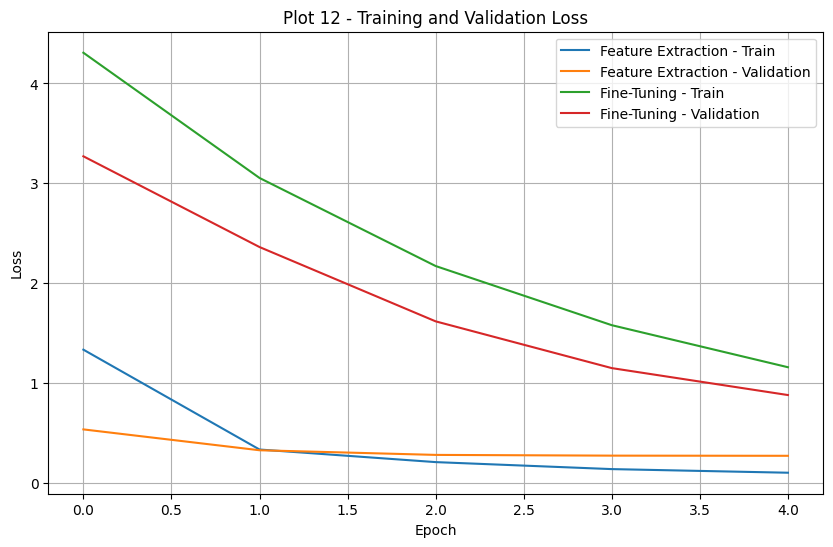

In [33]:

plt.figure(figsize=(10, 6))

plt.plot(
    feature_history.history["loss"],
    label="Feature Extraction - Train"
)

plt.plot(
    feature_history.history["val_loss"],
    label="Feature Extraction - Validation"
)

plt.plot(
    fine_history.history["loss"],
    label="Fine-Tuning - Train"
)

plt.plot(
    fine_history.history["val_loss"],
    label="Fine-Tuning - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Plot 12 - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [34]:

candidate_configs = {

    "C1_Baseline": {
        "learning_rate": 1e-3,
        "batch_size": 32,
        "dropout": 0,
        "optimizer": "adam"
    },

    "C2_Dropout": {
        "learning_rate": 1e-3,
        "batch_size": 32,
        "dropout": 0.25,
        "optimizer": "adam"
    },

    "C3_LowLR": {
        "learning_rate": 1e-4,
        "batch_size": 32,
        "dropout": 0.25,
        "optimizer": "adam"
    },

    "C4_SGD": {
        "learning_rate": 1e-3,
        "batch_size": 32,
        "dropout": 0.25,
        "optimizer": "sgd"
    }
}

candidate_configs

{'C1_Baseline': {'learning_rate': 0.001,
  'batch_size': 32,
  'dropout': 0,
  'optimizer': 'adam'},
 'C2_Dropout': {'learning_rate': 0.001,
  'batch_size': 32,
  'dropout': 0.25,
  'optimizer': 'adam'},
 'C3_LowLR': {'learning_rate': 0.0001,
  'batch_size': 32,
  'dropout': 0.25,
  'optimizer': 'adam'},
 'C4_SGD': {'learning_rate': 0.001,
  'batch_size': 32,
  'dropout': 0.25,
  'optimizer': 'sgd'}}

In [35]:

def dataset_to_numpy(dataset):

    images = []
    labels = []

    for image, label in dataset:

        image = tf.image.resize(
            image,
            IMG_SIZE
        )

        images.append(image.numpy())
        labels.append(label.numpy())

    images = np.array(images)
    labels = np.array(labels)

    return images, labels


X_cv, y_cv = dataset_to_numpy(ds_train)

print("X:", X_cv.shape)
print("y:", y_cv.shape)

X: (2944, 224, 224, 3)
y: (2944,)


In [36]:
X_cv = preprocess_input(X_cv.astype(np.float32))

print(
    "Range:",
    X_cv.min(),
    X_cv.max()
)

Range: -1.0 1.0


In [37]:

def run_5fold_cv(config):

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )

    fold_accuracies = []
    fold_times = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_cv, y_cv),
        start=1
    ):

        print("Fold:", fold)
        X_train_fold = X_cv[train_idx]
        y_train_fold = y_cv[train_idx]

        X_val_fold = X_cv[val_idx]
        y_val_fold = y_cv[val_idx]

        train_dataset = tf.data.Dataset.from_tensor_slices(
            (X_train_fold, y_train_fold)
        ).shuffle(
            1000,
            seed=SEED
        ).batch(
            config["batch_size"]
        ).prefetch(AUTOTUNE)

        val_dataset = tf.data.Dataset.from_tensor_slices(
            (X_val_fold, y_val_fold)
        ).batch(
            config["batch_size"]
        ).prefetch(AUTOTUNE)

        model = build_mobilenet_model(
            initialization="he",
            dropout_rate=config["dropout"],
            l2_strength=0,
            use_bn=True,
            optimizer_name=config["optimizer"],
            learning_rate=config["learning_rate"],
            train_base=False
        )

        start = time.time()

        history = model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=EPOCHS,
            verbose=1
        )

        elapsed = time.time() - start

        best_accuracy = max(
            history.history["val_accuracy"]
        ) * 100

        fold_accuracies.append(best_accuracy)
        fold_times.append(elapsed)

        print(
            f"Fold {fold} accuracy: "
            f"{best_accuracy:.2f}%"
        )

    mean_accuracy = np.mean(fold_accuracies)
    std_accuracy = np.std(
        fold_accuracies,
        ddof=1
    )

    mean_time = np.mean(fold_times)

    return {
        "fold_accuracies": fold_accuracies,
        "mean": mean_accuracy,
        "std": std_accuracy,
        "time": mean_time
    }

In [38]:

cv_results = {}

for name, config in candidate_configs.items():

    print("CONFIGURATION:", name)
    cv_results[name] = run_5fold_cv(config)

CONFIGURATION: C1_Baseline
Fold: 1
Epoch 1/5
73/74 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4295 - loss: 2.3421

2026-08-20 09:31:15.374954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:31:15.512412: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.4326 - loss: 2.3279

2026-08-20 09:31:30.864464: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:31:31.000993: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


74/74 ━━━━━━━━━━━━━━━━━━━━ 38s 385ms/step - accuracy: 0.6590 - loss: 1.2923 - val_accuracy: 0.8472 - val_loss: 0.6338
Epoch 2/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9261 - loss: 0.2482 - val_accuracy: 0.8761 - val_loss: 0.4027
Epoch 3/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9694 - loss: 0.1354 - val_accuracy: 0.8846 - val_loss: 0.3474
Epoch 4/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9847 - loss: 0.0850 - val_accuracy: 0.8896 - val_loss: 0.3282
Epoch 5/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9945 - loss: 0.0542 - val_accuracy: 0.8879 - val_loss: 0.3266
Fold 1 accuracy: 88.96%
Fold: 2
Epoch 1/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 23s 196ms/step - accuracy: 0.6527 - loss: 1.2445 - val_accuracy: 0.8336 - val_loss: 0.7096
Epoch 2/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9189 - loss: 0.2604 - val_accuracy: 0.8795 - val_loss: 0.4273
Epoch 3/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9673 - loss: 0.1371 - val_ac

2026-08-20 09:34:09.663714: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:34:09.801182: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.4274 - loss: 2.2498

2026-08-20 09:34:25.173938: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:34:25.324854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:34:25.461869: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


74/74 ━━━━━━━━━━━━━━━━━━━━ 38s 388ms/step - accuracy: 0.6452 - loss: 1.2808 - val_accuracy: 0.8435 - val_loss: 0.6644
Epoch 2/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9219 - loss: 0.2712 - val_accuracy: 0.8946 - val_loss: 0.3915
Epoch 3/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9656 - loss: 0.1405 - val_accuracy: 0.9014 - val_loss: 0.3285
Epoch 4/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9839 - loss: 0.0891 - val_accuracy: 0.8980 - val_loss: 0.2932
Epoch 5/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9936 - loss: 0.0595 - val_accuracy: 0.9116 - val_loss: 0.2844
Fold 5 accuracy: 91.16%
CONFIGURATION: C2_Dropout
Fold: 1
Epoch 1/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 25s 201ms/step - accuracy: 0.5809 - loss: 1.5660 - val_accuracy: 0.8489 - val_loss: 0.6770
Epoch 2/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8896 - loss: 0.3576 - val_accuracy: 0.8744 - val_loss: 0.4018
Epoch 3/5
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.93

In [39]:

cv_table = []

for name, result in cv_results.items():

    row = {
        "Configuration": name,
        "Fold 1": result["fold_accuracies"][0],
        "Fold 2": result["fold_accuracies"][1],
        "Fold 3": result["fold_accuracies"][2],
        "Fold 4": result["fold_accuracies"][3],
        "Fold 5": result["fold_accuracies"][4],
        "Mean Accuracy": result["mean"],
        "Std": result["std"],
        "Mean Training Time": result["time"]
    }

    cv_table.append(row)

cv_df = pd.DataFrame(cv_table)

display(cv_df)

,Configuration,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean Accuracy,Std,Mean Training Time
0,C1_Baseline,88.964349,89.303905,90.831918,90.492362,91.156465,90.149800,0.963955,40.199866
1,C2_Dropout,89.303905,88.624787,91.171479,91.001695,90.306121,90.081598,1.096806,36.083946
2,C3_LowLR,76.740235,74.702889,77.589136,77.249575,77.380955,76.732558,1.176974,35.715701
3,C4_SGD,56.027162,50.084889,54.668933,54.329371,51.530612,53.328193,2.441040,35.142105


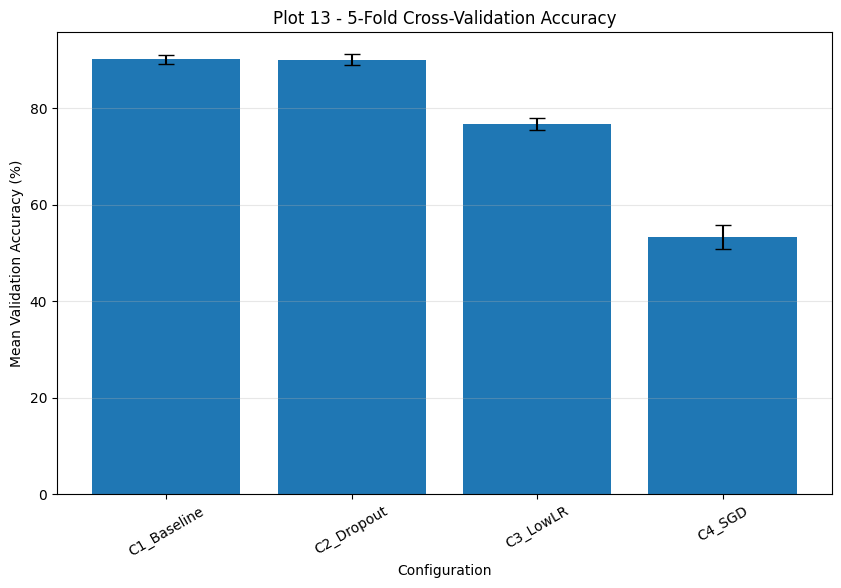

In [40]:

plt.figure(figsize=(10, 6))

plt.bar(
    cv_df["Configuration"],
    cv_df["Mean Accuracy"],
    yerr=cv_df["Std"],
    capsize=6
)

plt.ylabel("Mean Validation Accuracy (%)")
plt.xlabel("Configuration")
plt.title("Plot 13 - 5-Fold Cross-Validation Accuracy")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [41]:

best_idx = cv_df["Mean Accuracy"].idxmax()

best_configuration_name = cv_df.loc[
    best_idx,
    "Configuration"
]

best_configuration = candidate_configs[
    best_configuration_name
]

print("Best configuration:")
print(best_configuration_name)

print("\nParameters:")
print(best_configuration)

Best configuration:
C1_Baseline

Parameters:
{'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0, 'optimizer': 'adam'}


In [42]:

final_train_ds = prepare_dataset(
    ds_train_full,
    batch_size=best_configuration["batch_size"],
    shuffle=True
)

final_test_ds = prepare_dataset(
    ds_test,
    batch_size=best_configuration["batch_size"],
    shuffle=False
)

final_model = build_mobilenet_model(
    initialization="he",
    dropout_rate=best_configuration["dropout"],
    l2_strength=0,
    use_bn=True,
    optimizer_name=best_configuration["optimizer"],
    learning_rate=best_configuration["learning_rate"],
    train_base=False
)

final_history, final_training_time = train_model(
    final_model,
    final_train_ds,
    final_test_ds,
    epochs=EPOCHS
)

Epoch 1/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5213 - loss: 1.8295

2026-08-20 09:45:28.264799: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-20 09:45:28.402399: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


115/115 ━━━━━━━━━━━━━━━━━━━━ 36s 205ms/step - accuracy: 0.7264 - loss: 0.9519 - val_accuracy: 0.8673 - val_loss: 0.5011
Epoch 2/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9337 - loss: 0.2198 - val_accuracy: 0.8833 - val_loss: 0.3724
Epoch 3/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.9677 - loss: 0.1238 - val_accuracy: 0.8896 - val_loss: 0.3574
Epoch 4/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.9848 - loss: 0.0744 - val_accuracy: 0.8942 - val_loss: 0.3493
Epoch 5/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9946 - loss: 0.0466 - val_accuracy: 0.8934 - val_loss: 0.3600


In [43]:

final_train_ds = prepare_dataset(
    ds_train_full,
    batch_size=best_configuration["batch_size"],
    shuffle=True
)

# Use the existing validation data for monitoring
final_val_ds = prepare_dataset(
    ds_val,
    batch_size=best_configuration["batch_size"],
    shuffle=False
)

final_test_ds = prepare_dataset(
    ds_test,
    batch_size=best_configuration["batch_size"],
    shuffle=False
)

final_model = build_mobilenet_model(
    initialization="he",
    dropout_rate=best_configuration["dropout"],
    l2_strength=0,
    use_bn=True,
    optimizer_name=best_configuration["optimizer"],
    learning_rate=best_configuration["learning_rate"],
    train_base=False
)

final_history, final_training_time = train_model(
    final_model,
    final_train_ds,
    final_val_ds,
    epochs=EPOCHS
)

Epoch 1/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 111ms/step - accuracy: 0.7264 - loss: 0.9519 - val_accuracy: 0.9606 - val_loss: 0.2864
Epoch 2/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 68ms/step - accuracy: 0.9337 - loss: 0.2198 - val_accuracy: 0.9837 - val_loss: 0.1002
Epoch 3/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 68ms/step - accuracy: 0.9677 - loss: 0.1238 - val_accuracy: 0.9959 - val_loss: 0.0513
Epoch 4/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9848 - loss: 0.0744 - val_accuracy: 1.0000 - val_loss: 0.0282
Epoch 5/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9946 - loss: 0.0466 - val_accuracy: 1.0000 - val_loss: 0.0200


In [44]:

y_true = []
y_pred = []

for images, labels in final_test_ds:

    predictions = final_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [45]:

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

num_parameters = final_model.count_params()

final_results = pd.DataFrame({
    "Metric": [
        "Mean CV Accuracy",
        "CV Standard Deviation",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Training Time (seconds)",
        "Number of Parameters"
    ],

    "Value": [
        cv_df.loc[
            best_idx,
            "Mean Accuracy"
        ],

        cv_df.loc[
            best_idx,
            "Std"
        ],

        test_accuracy * 100,

        precision * 100,

        recall * 100,

        f1 * 100,

        final_training_time,

        num_parameters
    ]
})

display(final_results)

,Metric,Value
0,Mean CV Accuracy,9.014980e+01
1,CV Standard Deviation,9.639554e-01
2,Test Accuracy,8.934315e+01
3,Precision,8.977596e+01
4,Recall,8.934315e+01
5,F1-score,8.932576e+01
6,Training Time (seconds),7.391596e+01
7,Number of Parameters,2.310501e+06


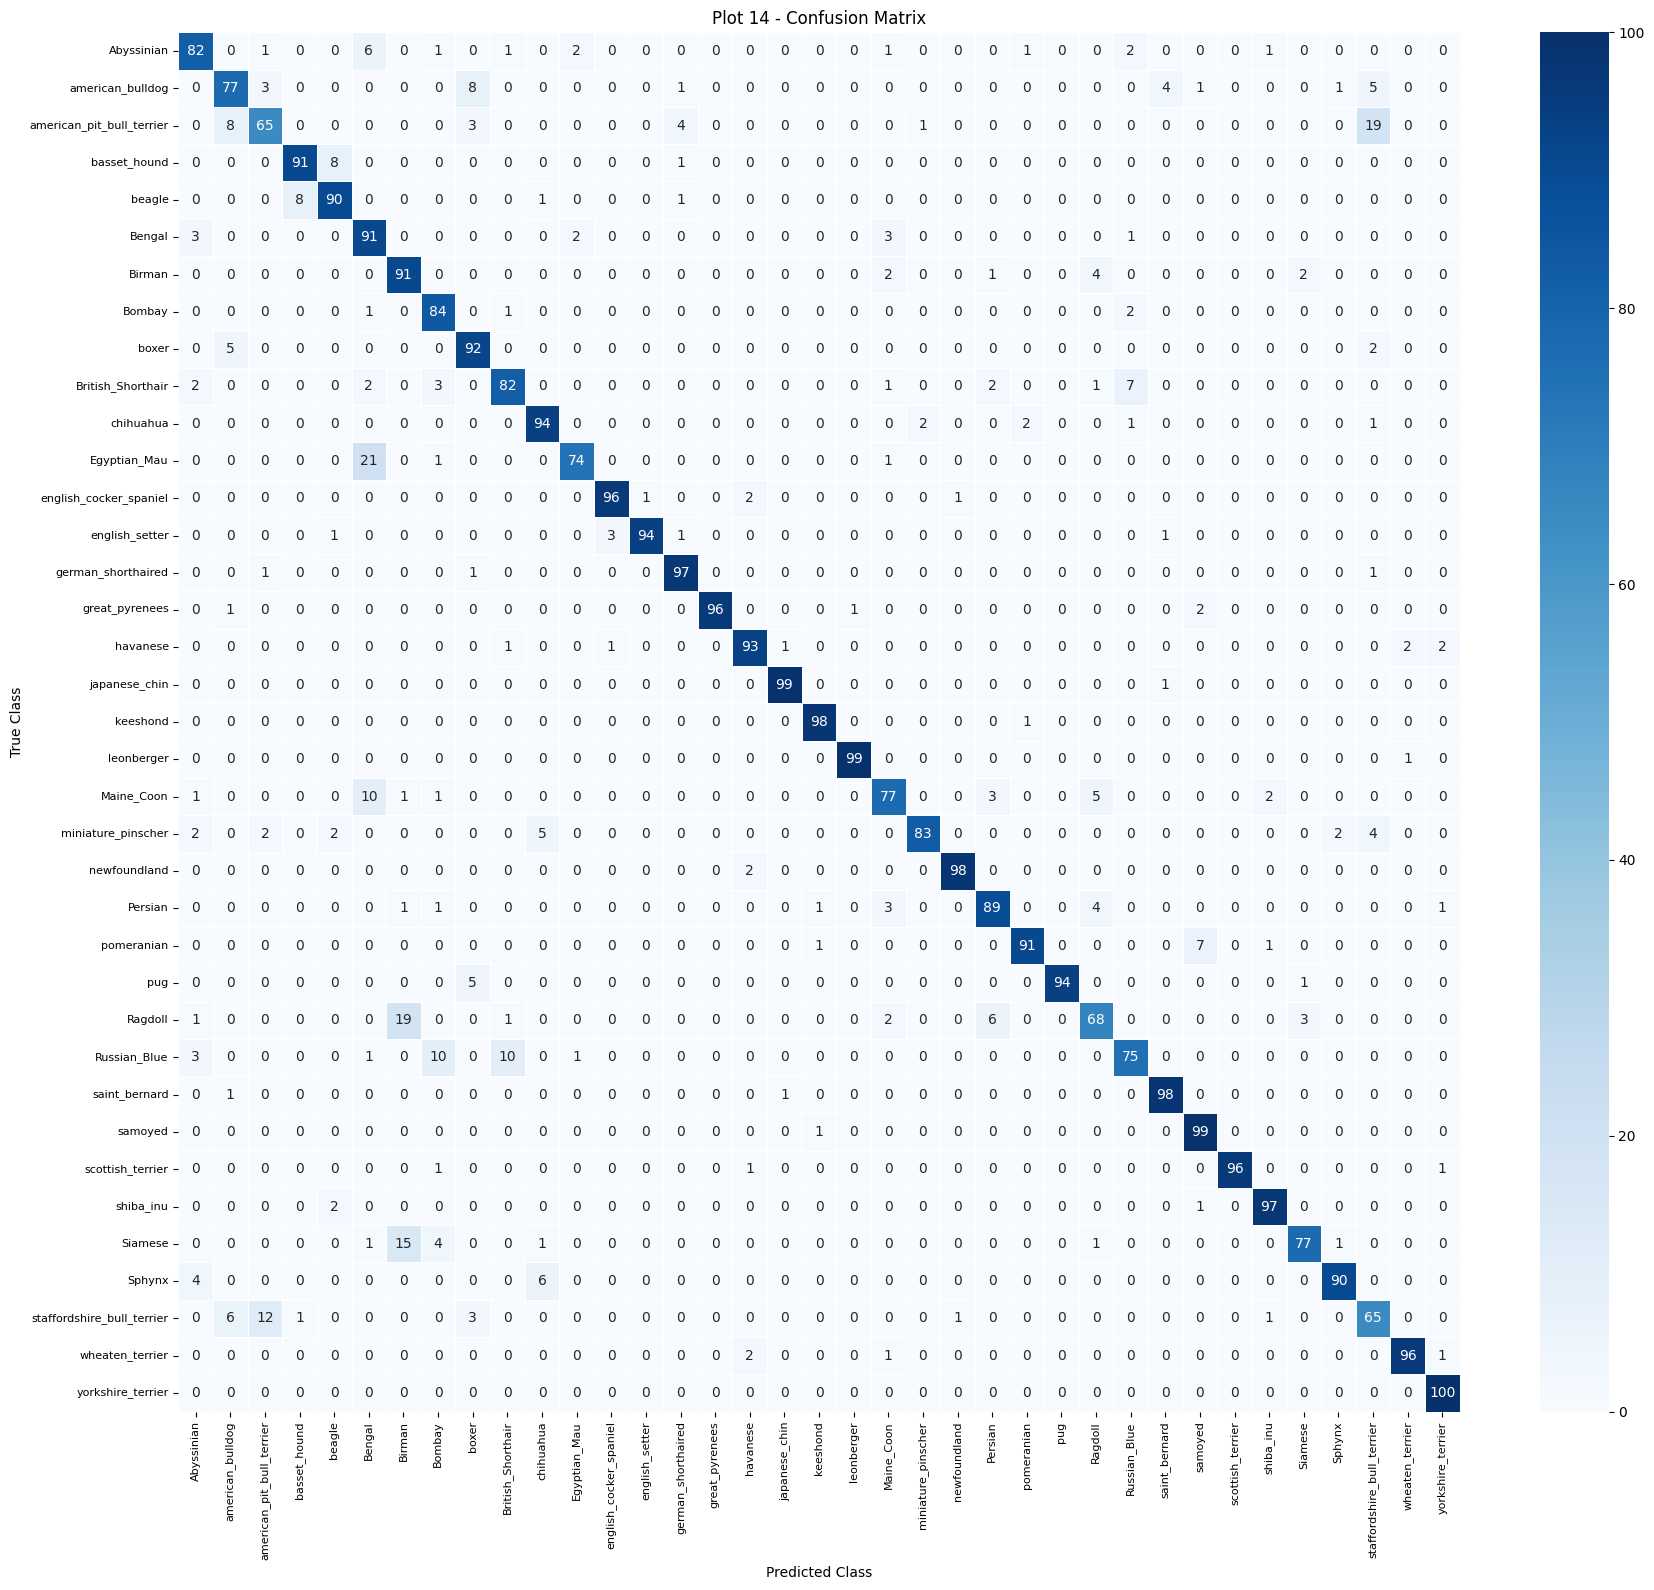

In [56]:
cm = confusion_matrix(
    y_true,
    y_pred
)

class_names = [
    ds_info.features["label"].int2str(i)
    for i in range(NUM_CLASSES)
]

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    annot=True,          # Show values
    fmt="d",             # Display as integers
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Plot 14 - Confusion Matrix")

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()
plt.show()

In [47]:

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

classification_df = pd.DataFrame(report).T

display(classification_df)

,precision,recall,f1-score,support
Abyssinian,0.836735,0.836735,0.836735,98.000000
american_bulldog,0.785714,0.770000,0.777778,100.000000
american_pit_bull_terrier,0.773810,0.650000,0.706522,100.000000
basset_hound,0.910000,0.910000,0.910000,100.000000
beagle,0.873786,0.900000,0.886700,100.000000
Bengal,0.684211,0.910000,0.781116,100.000000
Birman,0.716535,0.910000,0.801762,100.000000
Bombay,0.792453,0.954545,0.865979,88.000000
boxer,0.821429,0.929293,0.872038,99.000000
British_Shorthair,0.854167,0.820000,0.836735,100.000000


In [48]:

misclassified_indices = np.where(
    y_true != y_pred
)[0]

print(
    "Number of misclassified images:",
    len(misclassified_indices)
)

Number of misclassified images: 391


In [49]:

original_test_images = []

original_test_labels = []

for image, label in ds_test:

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    original_test_images.append(
        image.numpy().astype(np.uint8)
    )

    original_test_labels.append(
        label.numpy()
    )

original_test_images = np.array(
    original_test_images
)

original_test_labels = np.array(
    original_test_labels
)

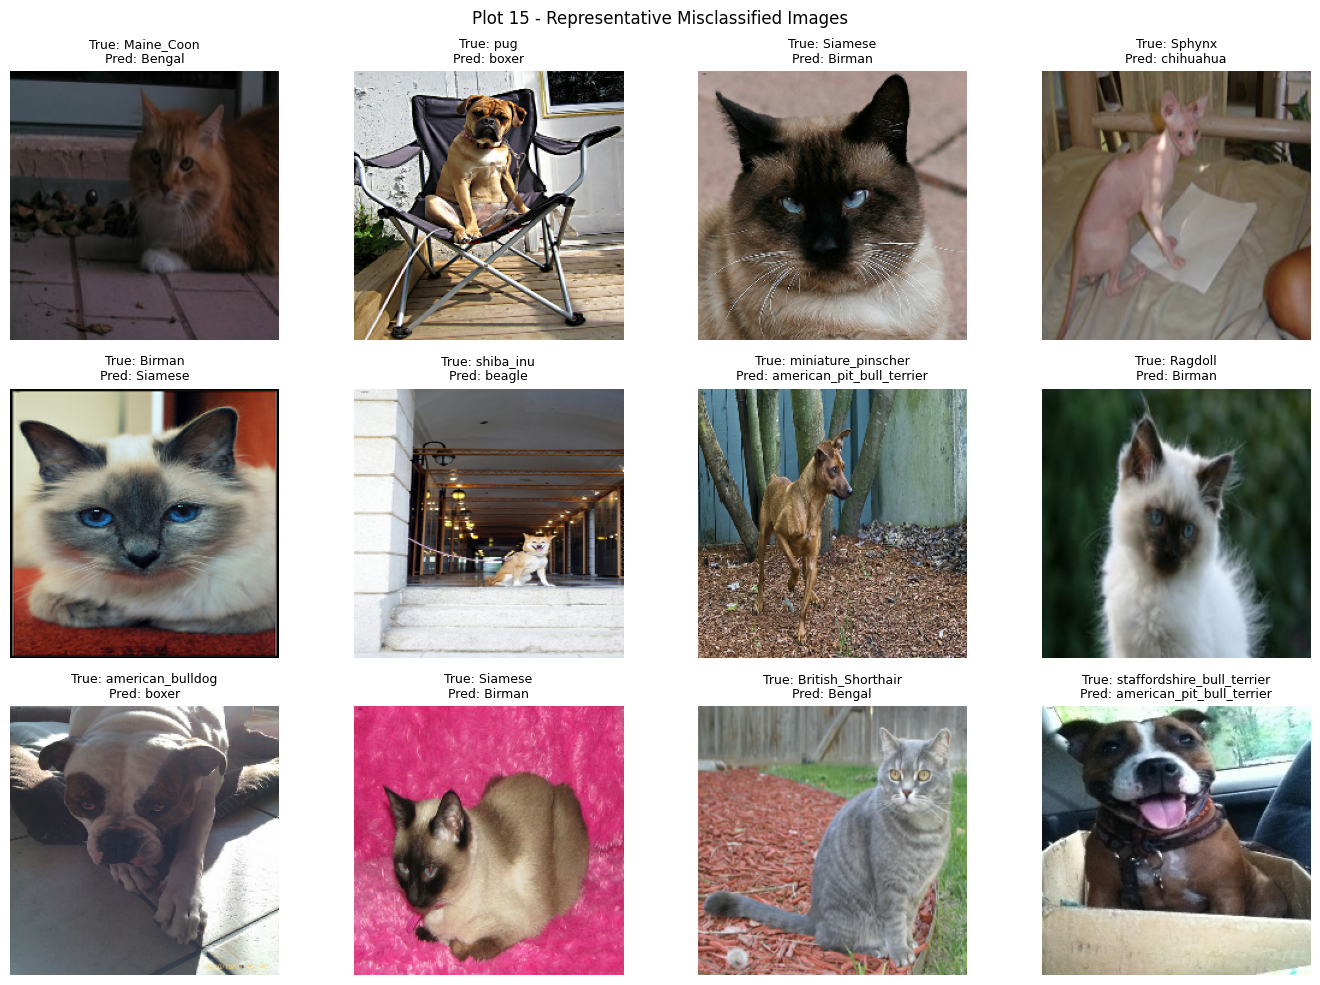

In [50]:

num_images = min(
    12,
    len(misclassified_indices)
)

plt.figure(figsize=(14, 10))

for i in range(num_images):

    idx = misclassified_indices[i]

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        original_test_images[idx]
    )

    true_name = class_names[
        y_true[idx]
    ]

    pred_name = class_names[
        y_pred[idx]
    ]

    plt.title(
        f"True: {true_name}\nPred: {pred_name}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "Plot 15 - Representative Misclassified Images"
)

plt.tight_layout()
plt.show()

In [51]:

cm_without_diagonal = cm.copy()

np.fill_diagonal(
    cm_without_diagonal,
    0
)

top_confusions = []

for _ in range(10):

    idx = np.unravel_index(
        np.argmax(cm_without_diagonal),
        cm_without_diagonal.shape
    )

    true_class = class_names[idx[0]]
    predicted_class = class_names[idx[1]]
    count = cm_without_diagonal[idx]

    top_confusions.append({
        "True Class": true_class,
        "Predicted Class": predicted_class,
        "Count": count
    })

    cm_without_diagonal[idx] = 0

top_confusions_df = pd.DataFrame(
    top_confusions
)

display(top_confusions_df)

,True Class,Predicted Class,Count
0,Egyptian_Mau,Bengal,21
1,american_pit_bull_terrier,staffordshire_bull_terrier,19
2,Ragdoll,Birman,19
3,Siamese,Birman,15
4,staffordshire_bull_terrier,american_pit_bull_terrier,12
5,Maine_Coon,Bengal,10
6,Russian_Blue,Bombay,10
7,Russian_Blue,British_Shorthair,10
8,american_bulldog,boxer,8
9,american_pit_bull_terrier,american_bulldog,8


In [52]:


overall_results = []

# ------------------------------------------------------------
# Baseline
# ------------------------------------------------------------

overall_results.append({
    "Configuration": "Baseline",
    "CV Accuracy": np.nan,
    "CV SD": np.nan,
    "Test Accuracy": np.nan,
    "Training Time": baseline_time
})

# ------------------------------------------------------------
# Best Initialization
# ------------------------------------------------------------

best_init = init_results_df[
    "Best Validation Accuracy"
].idxmax()

overall_results.append({
    "Configuration": "Best Initialization",
    "CV Accuracy": np.nan,
    "CV SD": np.nan,
    "Test Accuracy": np.nan,
    "Training Time":
        init_results_df.loc[
            best_init,
            "Training Time"
        ]
})

# ------------------------------------------------------------
# Best Regularization
# ------------------------------------------------------------

best_reg = regularization_df[
    "Best Val Accuracy"
].idxmax()

overall_results.append({
    "Configuration": "Best Regularization",
    "CV Accuracy": np.nan,
    "CV SD": np.nan,
    "Test Accuracy": np.nan,
    "Training Time":
        regularization_df.loc[
            best_reg,
            "Training Time"
        ]
})

# ------------------------------------------------------------
# Best Optimizer
# ------------------------------------------------------------

best_optimizer = optimizer_df[
    "Best Val Accuracy"
].idxmax()

overall_results.append({
    "Configuration": "Best Optimizer",
    "CV Accuracy": np.nan,
    "CV SD": np.nan,
    "Test Accuracy": np.nan,
    "Training Time":
        optimizer_df.loc[
            best_optimizer,
            "Training Time"
        ]
})

# ------------------------------------------------------------
# Best Hyperparameters
# ------------------------------------------------------------

overall_results.append({
    "Configuration": "Best Hyperparameters",
    "CV Accuracy":
        cv_df.loc[
            best_idx,
            "Mean Accuracy"
        ],

    "CV SD":
        cv_df.loc[
            best_idx,
            "Std"
        ],

    "Test Accuracy":
        test_accuracy * 100,

    "Training Time":
        final_training_time
})

# ------------------------------------------------------------
# Fine Tuned
# ------------------------------------------------------------

overall_results.append({
    "Configuration": "Fine-Tuned Model",
    "CV Accuracy": np.nan,
    "CV SD": np.nan,
    "Test Accuracy": np.nan,
    "Training Time": fine_time
})

overall_df = pd.DataFrame(
    overall_results
)

display(overall_df)

,Configuration,CV Accuracy,CV SD,Test Accuracy,Training Time
0,Baseline,NaN,NaN,NaN,80.068756
1,Best Initialization,NaN,NaN,NaN,70.282893
2,Best Regularization,NaN,NaN,NaN,70.089045
3,Best Optimizer,NaN,NaN,NaN,69.870371
4,Best Hyperparameters,90.1498,0.963955,89.343145,73.915964
5,Fine-Tuned Model,NaN,NaN,NaN,77.611668


In [53]:

hyperparameter_summary = pd.concat(
    [
        lr_df.rename(
            columns={
                "Learning Rate": "Value",
                "Validation Accuracy":
                    "Validation Accuracy"
            }
        ).assign(
            Hyperparameter="Learning Rate"
        )[[
            "Hyperparameter",
            "Value",
            "Validation Accuracy"
        ]],

        batch_df.rename(
            columns={
                "Batch Size": "Value"
            }
        ).assign(
            Hyperparameter="Batch Size"
        )[[
            "Hyperparameter",
            "Value",
            "Validation Accuracy"
        ]],

        dropout_df.rename(
            columns={
                "Dropout Rate": "Value"
            }
        ).assign(
            Hyperparameter="Dropout Rate"
        )[[
            "Hyperparameter",
            "Value",
            "Validation Accuracy"
        ]]
    ],
    ignore_index=True
)

display(hyperparameter_summary)

,Hyperparameter,Value,Validation Accuracy
0,Learning Rate,0.0010,91.576087
1,Learning Rate,0.0001,84.239131
2,Batch Size,16.0000,92.255437
3,Batch Size,32.0000,92.119563
4,Batch Size,64.0000,91.168481
5,Dropout Rate,0.0000,91.711956
6,Dropout Rate,0.2500,91.983694
7,Dropout Rate,0.5000,92.255437


In [54]:
# ============================================================
# CELL 36 - SAVE RESULTS
# ============================================================

init_results_df.to_csv(
    "initialization_results.csv"
)

regularization_df.to_csv(
    "regularization_results.csv"
)

optimizer_df.to_csv(
    "optimizer_results.csv"
)

lr_df.to_csv(
    "learning_rate_results.csv"
)

batch_df.to_csv(
    "batch_size_results.csv"
)

dropout_df.to_csv(
    "dropout_results.csv"
)

cv_df.to_csv(
    "cross_validation_results.csv"
)

final_results.to_csv(
    "final_model_results.csv"
)

overall_df.to_csv(
    "overall_results.csv"
)

print("All result files saved.")

All result files saved.


In [55]:

print("=" * 70)
print("FINAL MODEL SUMMARY")
print("=" * 70)

print(
    f"Best Configuration : {best_configuration_name}"
)

print(
    f"CV Accuracy        : "
    f"{cv_df.loc[best_idx, 'Mean Accuracy']:.2f}%"
)

print(
    f"CV Standard Dev.   : "
    f"{cv_df.loc[best_idx, 'Std']:.2f}%"
)

print(
    f"Test Accuracy      : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Precision          : "
    f"{precision * 100:.2f}%"
)

print(
    f"Recall             : "
    f"{recall * 100:.2f}%"
)

print(
    f"F1 Score           : "
    f"{f1 * 100:.2f}%"
)

print(
    f"Training Time      : "
    f"{final_training_time:.2f} seconds"
)

print(
    f"Parameters         : "
    f"{num_parameters:,}"
)

print("=" * 70)

FINAL MODEL SUMMARY
Best Configuration : C1_Baseline
CV Accuracy        : 90.15%
CV Standard Dev.   : 0.96%
Test Accuracy      : 89.34%
Precision          : 89.78%
Recall             : 89.34%
F1 Score           : 89.33%
Training Time      : 73.92 seconds
Parameters         : 2,310,501
